<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6b_quaternions_sistemas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio VI (b): sistemas de equações com quaternions

## A orientação de um satélite como um autovetor, nuvens de pontos 3D e a média de rotações

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 6](X6_quaternions.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_quaternions.ipynb)) · **Anterior:** [X6a_quaternions_algebra.ipynb](X6a_quaternions_algebra.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6a_quaternions_algebra.ipynb)) · **Próximo:** [X6c_quaternions_edo.ipynb](X6c_quaternions_edo.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6c_quaternions_edo.ipynb))

**Objetivo.** No domínio V, alinhar duas nuvens de pontos do plano (o problema de Procrustes) coube numa linha de números complexos. No espaço, o problema correspondente tem uma solução tão elegante quanto, e mais surpreendente: a rotação ótima é o **autovetor** de uma matriz simétrica $4\times4$. Um problema não linear, com a restrição $R^\top R=I$, vira um problema de autovalores, que a álgebra linear resolve de forma confiável. A razão é que $R(q)$ é **quadrática** em $q$: qualquer soma de produtos escalares $\mathbf r\cdot R(q)\,\mathbf b$ é uma forma quadrática $q^\top Kq$, e maximizar uma forma quadrática na esfera unitária é achar o maior autovalor.

**Roteiro**
1. O problema de Wahba: a atitude de um satélite a partir de direções medidas
2. Três soluções: TRIAD, o método q de Davenport, e o SVD
3. Quão bem: a covariância da atitude, conferida por Monte Carlo
4. Nuvens de pontos 3D: a orientação absoluta de Horn e o ICP
5. A média de rotações: por que somar quaternions não funciona
6. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

from scipy.spatial import cKDTree
rng = np.random.default_rng(62)

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

def qmul(a, b):
    """Produto de Hamilton de quaternions guardados como arrays (w, x, y, z); aceita pilhas (..., 4)."""
    a, b = np.asarray(a), np.asarray(b)
    w1, x1, y1, z1 = np.moveaxis(a, -1, 0); w2, x2, y2, z2 = np.moveaxis(b, -1, 0)
    return np.stack([w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2,
                     w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2,
                     w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2,
                     w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2], axis=-1)

def qconj(q):
    q = np.asarray(q); return q * np.array([1, -1, -1, -1])

def qnorm(q):
    q = np.asarray(q, float); return q / np.linalg.norm(q, axis=-1, keepdims=True)

def qrot(q, v):
    """O vetor v (3,) levado pela rotação q: a parte vetorial de q (0, v) q*."""
    return qmul(qmul(q, np.concatenate([[0.0], v])), qconj(q))[1:]

def qmat(q):
    """A matriz de rotação R(q), com R v = q v q* (q unitário)."""
    w, x, y, z = q
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)],
                     [2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)],
                     [2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)]])

def mat_q(R):
    """De uma matriz de rotação para um quaternion (método de Shepperd: usa o maior pivô, sem perder dígitos)."""
    t = np.trace(R); d = np.diag(R)
    k = np.argmax([t, *d])
    if k == 0:
        w = np.sqrt(1 + t) / 2; q = [w, (R[2, 1] - R[1, 2]) / (4 * w), (R[0, 2] - R[2, 0]) / (4 * w), (R[1, 0] - R[0, 1]) / (4 * w)]
    elif k == 1:
        x = np.sqrt(1 + 2 * d[0] - t) / 2; q = [(R[2, 1] - R[1, 2]) / (4 * x), x, (R[0, 1] + R[1, 0]) / (4 * x), (R[0, 2] + R[2, 0]) / (4 * x)]
    elif k == 2:
        y = np.sqrt(1 + 2 * d[1] - t) / 2; q = [(R[0, 2] - R[2, 0]) / (4 * y), (R[0, 1] + R[1, 0]) / (4 * y), y, (R[1, 2] + R[2, 1]) / (4 * y)]
    else:
        z = np.sqrt(1 + 2 * d[2] - t) / 2; q = [(R[1, 0] - R[0, 1]) / (4 * z), (R[0, 2] + R[2, 0]) / (4 * z), (R[1, 2] + R[2, 1]) / (4 * z), z]
    q = np.array(q); return q if q[0] >= 0 else -q

def qexp(phi):
    """Exp do vetor de rotação φ = θ n: (cos(θ/2), sen(θ/2) n), com o sinc estável perto de θ = 0."""
    phi = np.asarray(phi, float); th = np.linalg.norm(phi)
    return np.concatenate([[np.cos(th / 2)], 0.5 * sinc(th / 2) * phi])

def qlog(q):
    """Log: o vetor de rotação φ de q (escolhendo o representante com w ≥ 0, isto é, |θ| ≤ π)."""
    q = np.asarray(q, float)
    if q[0] < 0: q = -q
    s = np.linalg.norm(q[1:]); th = 2 * np.arctan2(s, q[0])     # atan2: estável para ângulos pequenos e grandes
    return 2 * q[1:] / sinc(th / 2)

def slerp(q0, q1, s):
    """Interpolação esférica: q0 Exp(s Log(q0* q1)), pelo arco mais curto."""
    return qmul(q0, qexp(s * qlog(qmul(qconj(q0), q1))))

def chapeu(v):
    """A matriz antissimétrica [v]×, com [v]× u = v × u."""
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

def unit(v): return np.asarray(v, float) / np.linalg.norm(v, axis=-1, keepdims=True)
def angulo_entre(a, b): return np.linalg.norm(qlog(qmul(qconj(a), b)))

---

## 1. O problema de Wahba

Um satélite conhece, no referencial do mundo (inercial), as direções $\mathbf r_k$ de alguns objetos: o Sol, o campo magnético da Terra no ponto da órbita, algumas estrelas. Os sensores a bordo medem as mesmas direções no referencial do satélite: $\mathbf b_k$. Se $R$ é a orientação do satélite (corpo → mundo), sem ruído valeria $\mathbf b_k=R^\top\mathbf r_k$. Com ruído, Grace Wahba (1965) propôs a rotação que minimiza

$$L(R)=\tfrac12\sum_k a_k\,\lvert\mathbf b_k-R^\top\mathbf r_k\rvert^2=\text{const}-\sum_k a_k\,\mathbf r_k\cdot R\,\mathbf b_k,$$

com pesos $a_k=1/\sigma_k^2$. Minimizar $L$ é maximizar $g(R)=\sum_k a_k\,\mathbf r_k\cdot R\,\mathbf b_k$. O cenário: um sensor de Sol (0,5°), um magnetômetro (2°, o campo da Terra é mal modelado) e um rastreador de estrelas vendo três estrelas (10 segundos de arco, ou seja, 0,003°).

In [2]:
q_ver = qnorm(rng.normal(size=4))
R_ver = qmat(q_ver)
SIG = np.radians(np.array([0.5, 2.0, 10 / 3600, 10 / 3600, 10 / 3600]))
nomes = ["Sol", "campo magnético", "estrela 1", "estrela 2", "estrela 3"]
r = unit(rng.normal(size=(5, 3)))                         # direções conhecidas no mundo
r[3:] = unit(r[2] + 0.08 * rng.normal(size=(2, 3)))         # as três estrelas estão no mesmo campo de visão (uns 5°)

def mede(r, R, sig, rng):
    """b = Rᵀ r, perturbado por uma pequena rotação aleatória de desvio sig (em cada eixo transversal)."""
    b = r @ R                                               # cada linha: Rᵀ r_k
    out = []
    for bk, s in zip(b, sig):
        out.append(qrot(qexp(s * rng.normal(size=3)), bk))
    return unit(np.array(out))

b = mede(r, R_ver, SIG, rng)
a = 1 / SIG**2
sep = lambda u, v: np.degrees(np.arccos(np.clip(u @ v, -1, 1)))
print(f"separações: Sol–campo {sep(r[0], r[1]):.1f}°;  estrela 1–2 {sep(r[2], r[3]):.1f}°, 1–3 {sep(r[2], r[4]):.1f}°;  Sol–estrela 1 {sep(r[0], r[2]):.1f}°")
for k_ in range(5):
    print(f"{nomes[k_]:16s}: σ = {np.degrees(SIG[k_]) * 3600:8.1f}″;  erro desta medida {np.degrees(np.arccos(np.clip(b[k_] @ (R_ver.T @ r[k_]), -1, 1))) * 3600:8.1f}″")

separações: Sol–campo 15.4°;  estrela 1–2 14.3°, 1–3 2.1°;  Sol–estrela 1 64.7°
Sol             : σ =   1800.0″;  erro desta medida   1800.9″
campo magnético : σ =   7200.0″;  erro desta medida   6961.3″
estrela 1       : σ =     10.0″;  erro desta medida      6.7″
estrela 2       : σ =     10.0″;  erro desta medida      9.8″
estrela 3       : σ =     10.0″;  erro desta medida     12.8″


---

## 2. Três soluções

**TRIAD** (anos 1960, ainda usado): usa só **duas** direções. Monta-se um triedro ortonormal com $\mathbf r_1$, $\mathbf r_1\times\mathbf r_2$ e o terceiro eixo, e o mesmo com $\mathbf b_1,\mathbf b_2$; a rotação leva um triedro no outro. A primeira direção é obedecida exatamente, a segunda só no que sobra. É rápido e não usa os pesos.

**O método q de Davenport** (1968): como $R(q)$ é quadrática em $q$, $g=q^\top Kq$ com

$$B=\sum_k a_k\,\mathbf b_k\mathbf r_k^\top,\quad \sigma=\mathrm{tr}\,B,\quad S=B+B^\top,\quad \mathbf z=\begin{bmatrix}B_{23}-B_{32}\\B_{31}-B_{13}\\B_{12}-B_{21}\end{bmatrix},\quad K=\begin{bmatrix}S-\sigma I&\mathbf z\\\mathbf z^\top&\sigma\end{bmatrix},$$

escrita para $q=(\mathbf e,q_4)$, com a parte vetorial primeiro, como na literatura de atitude. O máximo de $q^\top Kq$ com $|q|=1$ é o autovetor do **maior autovalor**, e é a atitude ótima. Não há chute inicial, não há iteração, não há mínimo local.

**O SVD** (Markley, 1988): com $B=U\Sigma V^\top$, a atitude (mundo → corpo) é $U\,\mathrm{diag}(1,1,\det U\det V)\,V^\top$. É o mesmo Procrustes do domínio V, em 3D.

O método q e o SVD resolvem o **mesmo** problema exatamente; têm de dar a mesma rotação.

In [3]:
def triad(r1, r2, b1, b2):
    def triedro(u, v):
        t1 = unit(u); t2 = unit(np.cross(u, v)); return np.column_stack([t1, t2, np.cross(t1, t2)])
    return triedro(r1, r2) @ triedro(b1, b2).T            # R (corpo → mundo): leva o triedro de b no de r

def davenport(r, b, a):
    B = sum(ak * np.outer(bk, rk) for ak, rk, bk in zip(a, r, b))
    sig = np.trace(B); S = B + B.T
    z = np.array([B[1, 2] - B[2, 1], B[2, 0] - B[0, 2], B[0, 1] - B[1, 0]])
    K = np.zeros((4, 4)); K[:3, :3] = S - sig * np.eye(3); K[:3, 3] = z; K[3, :3] = z; K[3, 3] = sig
    lam, V = np.linalg.eigh(K)
    e, q4 = V[:3, -1], V[3, -1]
    q = np.concatenate([[q4], e])                          # para a ordem (w, x, y, z) deste domínio
    return (q if q[0] >= 0 else -q), lam

def wahba_svd(r, b, a):
    B = sum(ak * np.outer(bk, rk) for ak, rk, bk in zip(a, r, b))
    U, s, Vt = np.linalg.svd(B)
    A = U @ np.diag([1, 1, np.linalg.det(U) * np.linalg.det(Vt)]) @ Vt     # atitude mundo → corpo
    return A.T

q_dav, lam = davenport(r, b, a)
R_svd = wahba_svd(r, b, a)
R_tri = triad(r[0], r[1], b[0], b[1])
R_tri_estrelas = triad(r[2], r[3], b[2], b[3])
confere("o método q e o SVD dão a mesma rotação", qmat(q_dav), R_svd, tol=1e-9)
confere("o autovalor máximo é o valor máximo de g", lam[-1], sum(ak * rk @ (R_svd @ bk) for ak, rk, bk in zip(a, r, b)), tol=1e-6, relativo=True)
erro = lambda R_: np.degrees(angulo_entre(mat_q(R_), q_ver)) * 3600
print(f"erro de atitude:  Davenport {erro(qmat(q_dav)):7.1f}″;  SVD {erro(R_svd):7.1f}″;  "
      f"TRIAD (Sol, campo) {erro(R_tri):8.1f}″;  TRIAD (duas estrelas) {erro(R_tri_estrelas):7.1f}″")

OK   o método q e o SVD dão a mesma rotação:  diferença máxima = 1.23e-14
OK   o autovalor máximo é o valor máximo de g:  diferença relativa máxima = 1.87e-16
erro de atitude:  Davenport     7.7″;  SVD     7.7″;  TRIAD (Sol, campo)   1916.6″;  TRIAD (duas estrelas)     9.5″


**Para pensar.** O TRIAD com o Sol e o campo magnético erra quase 2000″, porque as duas direções estão a só 15° uma da outra: o giro em torno do Sol é decidido pela componente do campo perpendicular ao Sol, que é pequena, e o erro de 2° do magnetômetro é ampliado por $1/\mathrm{sen}\,15°\approx4$. Com duas estrelas, o TRIAD fica perto do ótimo, porque elas são medidas com uma precisão centenas de vezes maior. O método q, com as cinco medidas e os pesos certos, é melhor que os dois. A seção 3 mede quanto, com muitas repetições.

---

## 3. Quão bem: a covariância da atitude

Escrevendo o erro como uma pequena rotação no corpo, $R_{\text{est}}=R\,\mathrm{Exp}(\boldsymbol\delta)$, a covariância de $\boldsymbol\delta$ para o estimador de Wahba é, em primeira ordem (Shuster, 1989),

$$P_{\delta\delta}=\Big(\sum_k\frac1{\sigma_k^2}\big(I-\mathbf b_k\mathbf b_k^\top\big)\Big)^{-1}.$$

Cada medida informa só sobre os **dois** eixos perpendiculares a ela ($I-\mathbf b\mathbf b^\top$ projeta no plano transversal): girar em torno da própria direção medida não muda a medida. É a mesma estrutura $\mathbf J^\top\mathbf R^{-1}\mathbf J$ de Gauss–Newton (notebook II(b)) e do filtro de Kalman. Monte Carlo com 4000 repetições confere a fórmula e compara os três métodos.

In [4]:
P_teo = np.linalg.inv(sum((1 / s**2) * (np.eye(3) - np.outer(bk, bk)) for s, bk in zip(SIG, r @ R_ver)))
erros = {"Davenport": [], "TRIAD (Sol, campo)": [], "TRIAD (2 estrelas)": []}
for _ in range(4000):
    bb = mede(r, R_ver, SIG, rng)
    qd, _ = davenport(r, bb, a)
    erros["Davenport"].append(qlog(qmul(qconj(q_ver), qd)))
    erros["TRIAD (Sol, campo)"].append(qlog(qmul(qconj(q_ver), mat_q(triad(r[0], r[1], bb[0], bb[1])))))
    erros["TRIAD (2 estrelas)"].append(qlog(qmul(qconj(q_ver), mat_q(triad(r[2], r[3], bb[2], bb[3])))))
D = np.array(erros["Davenport"])
P_mc = np.cov(D.T)
seg = lambda x: np.degrees(x) * 3600
print("desvios-padrão por eixo do corpo (segundos de arco):")
print(f"   fórmula de Shuster:  {seg(np.sqrt(np.diag(P_teo)))}")
print(f"   Monte Carlo:         {seg(np.sqrt(np.diag(P_mc)))}")
confere("a covariância de Monte Carlo bate com a fórmula (a menos de 10%)", np.diag(P_mc) / np.diag(P_teo), np.ones(3), tol=0.1)
for nome, E in erros.items():
    print(f"{nome:20s}: erro RMS {seg(np.sqrt(np.mean(np.sum(np.array(E)**2, axis=1)))):9.1f}″")
w_, V_ = np.linalg.eigh(P_teo)
print(f"o eixo pior determinado faz {np.degrees(np.arccos(abs(V_[:, -1] @ (R_ver.T @ unit(r[2] + r[3]))))):.1f}° com a direção média das estrelas, "
      f"e tem desvio {seg(np.sqrt(w_[-1])):.1f}″, contra {seg(np.sqrt(w_[0])):.1f}″ do melhor")

desvios-padrão por eixo do corpo (segundos de arco):
   fórmula de Shuster:  [25.816491 33.897372 27.381592]
   Monte Carlo:         [26.085921 34.117916 27.733103]
OK   a covariância de Monte Carlo bate com a fórmula (a menos de 10%):  diferença máxima = 2.58e-02
Davenport           : erro RMS      51.1″
TRIAD (Sol, campo)  : erro RMS   28216.5″
TRIAD (2 estrelas)  : erro RMS      58.4″
o eixo pior determinado faz 2.3° com a direção média das estrelas, e tem desvio 50.0″, contra 5.8″ do melhor


**Leitura.** A fórmula de Shuster prevê desvios de 26″, 34″ e 27″ nos três eixos do corpo, e o Monte Carlo dá 26″, 34″ e 28″: concordam a menos de 3%. Em 4000 repetições, o método q erra 51″ (RMS), o TRIAD com duas estrelas 58″, e o TRIAD com o Sol e o campo magnético 28 mil segundos de arco (quase 8°, o efeito da geometria ruim). Repare que a vantagem do método q sobre o TRIAD com estrelas é de só 13%: quase toda a informação vem das estrelas, e o Sol e o campo, com erros centenas de vezes maiores, pesam pouco.

A covariância não é redonda. O eixo pior determinado faz 2° com a direção média das estrelas, e tem desvio de 50″, contra 6″ do melhor: girar o satélite em torno da linha de visada do rastreador quase não move as estrelas, que estão todas perto dela. É por isso que satélites de precisão levam **dois** rastreadores de estrelas, apontados em direções diferentes. O $I-\mathbf b\mathbf b^\top$ da fórmula diz exatamente isso, e é a mesma conta que o filtro de Kalman da etapa (d) faz a cada medida.

---

## 4. Nuvens de pontos 3D: Horn e o ICP

Um LiDAR, uma câmera de profundidade ou um scanner de laboratório produzem **nuvens de pontos** 3D. Alinhar duas nuvens (uma peça escaneada contra o seu modelo CAD, dois *scans* consecutivos de um robô) é achar a rotação $R$ e a translação $\mathbf t$ que minimizam $\sum_k|\mathbf y_k-(R\,\mathbf x_k+\mathbf t)|^2$ para pares $(\mathbf x_k,\mathbf y_k)$ correspondentes. Horn (1987) mostrou, com quaternions: a translação ótima leva o centroide de $\mathbf x$ no de $\mathbf y$, e a rotação é a de Wahba para os pontos centrados (direções de comprimentos diferentes, com peso 1). É a **orientação absoluta**.

Sem saber quem corresponde a quem, o **ICP** (*Iterative Closest Point*) alterna: casar cada ponto com o vizinho mais próximo na outra nuvem, resolver Horn, repetir. Como no plano (domínio V), o ICP converge para um mínimo local, e a pergunta é: a partir de que rotação inicial ele ainda acerta?

O objeto: pontos sobre a superfície de um elipsoide de semieixos 3, 2 e 1, com uma saliência de um lado (para que não haja simetrias). O **modelo** (como um arquivo CAD) tem 20 000 pontos; a **medida** (o *scan*) tem 1 000 pontos, amostrados de novo (não os mesmos), com ruído de 1 cm, girada e transladada. O ICP leva a medida ao modelo.

In [5]:
def objeto(n, rng):
    """Pontos na superfície de um elipsoide (3, 2, 1) com uma saliência perto de +x+y+z."""
    d = unit(rng.normal(size=(n, 3)))
    bump = 1 + 0.6 * np.exp(-np.sum((d - unit([1, 1, 1]))**2, axis=1) / 0.15)
    return d * np.array([3.0, 2.0, 1.0]) * bump[:, None]

def horn(X, Y):
    """Rotação e translação que levam X em Y (pares correspondentes), pelo autovetor de Davenport."""
    cx, cy = X.mean(0), Y.mean(0)
    q, _ = davenport(Y - cy, X - cx, np.ones(len(X)))        # b_k = Rᵀ r_k  ⇔  r = y, b = x
    return q, cy - qmat(q) @ cx

X = objeto(500, rng)
q_t, t_t = qnorm(rng.normal(size=4)), np.array([0.5, -1.0, 2.0])
Y = X @ qmat(q_t).T + t_t + 0.01 * rng.normal(size=X.shape)
qh, th_ = horn(X, Y)
confere("Horn recupera a rotação (pares conhecidos, ruído de 1 cm)", np.degrees(angulo_entre(qh, q_t)) < 0.1, True)
confere("e a translação (a menos de 2 mm)", np.linalg.norm(th_ - t_t) < 2e-3, True)

def icp(X, Y, q0, t0, it_max=200):
    """Alinha a nuvem X à nuvem Y (densa). Devolve (q, t) com Y ≈ R(q) X + t."""
    arvore = cKDTree(Y); q_, t_ = q0, t0
    for it in range(it_max):
        Xt = X @ qmat(q_).T + t_
        d, idx = arvore.query(Xt)
        dq, dt_ = horn(Xt, Y[idx])
        q_, t_ = qmul(dq, q_), qmat(dq) @ t_ + dt_
        if angulo_entre(dq, [1, 0, 0, 0]) < 1e-9: break
    return q_, t_, np.sqrt(np.mean(d**2)), it + 1

# o modelo (CAD): 20 000 pontos; a medida (scan): 1 000 pontos, girados e transladados, com ruído de 1 cm.
# o ICP leva a medida ao modelo; a orientação do objeto é a inversa do resultado.
modelo = objeto(20000, rng)
medida = objeto(1000, rng) @ qmat(q_t).T + t_t + 0.01 * rng.normal(size=(1000, 3))

def alinha(chute):
    q0 = qconj(chute); t0 = modelo.mean(0) - qmat(q0) @ medida.mean(0)
    q_, t_, rms_, n_ = icp(medida, modelo, q0, t0)
    return qconj(q_), rms_, n_

q_icp, rms, n_it = alinha(qmul(q_t, qexp([0.3, -0.2, 0.25])))
print(f"ICP a partir de um chute a {np.degrees(np.linalg.norm([0.3, -0.2, 0.25])):.0f}°: {n_it} iterações, erro de rotação "
      f"{np.degrees(angulo_entre(q_icp, q_t)):.2f}°, distância RMS final {rms * 100:.2f} cm")
confere("o ICP acerta a partir de um chute razoável (erro < 3°)", np.degrees(angulo_entre(q_icp, q_t)) < 3, True)

OK   Horn recupera a rotação (pares conhecidos, ruído de 1 cm):  diferença máxima = 0.00e+00
OK   e a translação (a menos de 2 mm):  diferença máxima = 0.00e+00


ICP a partir de um chute a 25°: 77 iterações, erro de rotação 0.88°, distância RMS final 3.16 cm
OK   o ICP acerta a partir de um chute razoável (erro < 3°):  diferença máxima = 0.00e+00


chute a  15° da verdade: o ICP acerta em 100% das 20 tentativas
chute a  30° da verdade: o ICP acerta em 100% das 20 tentativas
chute a  45° da verdade: o ICP acerta em 100% das 20 tentativas
chute a  60° da verdade: o ICP acerta em 100% das 20 tentativas
chute a  90° da verdade: o ICP acerta em  90% das 20 tentativas
chute a 120° da verdade: o ICP acerta em   5% das 20 tentativas
chute a 150° da verdade: o ICP acerta em   0% das 20 tentativas
chute a 180° da verdade: o ICP acerta em   0% das 20 tentativas
quando acerta, o erro de rotação fica entre 0.37° e 0.93°
OK   o ICP sempre acerta com chutes de até 45°:  diferença máxima = 0.00e+00


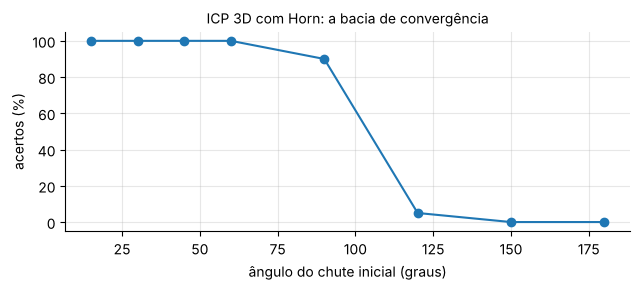

In [6]:
angs = [15, 30, 45, 60, 90, 120, 150, 180]
taxa, erros_ok = [], []
for graus in angs:
    acertos = 0
    for _ in range(20):
        q_, _, _ = alinha(qmul(q_t, qexp(np.radians(graus) * unit(rng.normal(size=3)))))
        e_ = np.degrees(angulo_entre(q_, q_t))
        if e_ < 3: acertos += 1; erros_ok.append(e_)
    taxa.append(acertos / 20)
for g_, t_ in zip(angs, taxa):
    print(f"chute a {g_:3d}° da verdade: o ICP acerta em {100 * t_:3.0f}% das 20 tentativas")
print(f"quando acerta, o erro de rotação fica entre {min(erros_ok):.2f}° e {max(erros_ok):.2f}°")
confere("o ICP sempre acerta com chutes de até 45°", min(taxa[:3]), 1.0)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(angs, 100 * np.array(taxa), "o-"); ax.set_xlabel("ângulo do chute inicial (graus)"); ax.set_ylabel("acertos (%)")
ax.set_title("ICP 3D com Horn: a bacia de convergência", fontsize=10); plt.tight_layout(); plt.show()

**Leitura.** Com os pares conhecidos, Horn recupera rotação e translação em uma conta. Sem os pares, o ICP acerta sempre com chutes de até 60°, em 90% dos casos a 90°, e quase nunca a partir de 120°: a bacia de convergência é bem maior que a do ICP no plano (domínio V), porque o objeto não tem simetrias e a saliência guia o alinhamento. Quando acerta, o erro de rotação fica entre 0,4° e 0,9°, bem acima do que o ruído de 1 cm explicaria. O erro que sobra vem da **amostragem**: o ICP ponto a ponto casa cada ponto medido com um ponto do modelo, e os pontos do modelo ficam a uns 3 cm uns dos outros (é a distância RMS final). Com o modelo mais denso, o erro cai; a variante ponto a plano, que casa cada ponto com o plano tangente do modelo, elimina quase todo esse viés (exercício 6).

---

## 5. A média de rotações

Vários sensores, ou várias medidas no tempo, dão estimativas $q_1,\dots,q_N$ da mesma orientação. Qual é a média? Três candidatas:
- **ingênua:** somar as componentes e normalizar. Funciona quando todos os $q_i$ estão do mesmo lado da esfera, mas $q$ e $-q$ são a mesma rotação, e um algoritmo que devolve "o representante com $w\ge0$" (como `mat_q` ou um sensor) pode entregar sinais misturados;
- **de Markley** (2007): o autovetor do maior autovalor de $M=\sum_iq_iq_i^\top$. Como $q_iq_i^\top=(-q_i)(-q_i)^\top$, o sinal não importa;
- **geodésica** (média de Karcher): o ponto $\bar q$ em que os $\mathrm{Log}(\bar q^*q_i)$ somam zero, achado por Gauss–Newton no grupo: $\bar q\leftarrow\bar q\,\mathrm{Exp}\big(\tfrac1N\sum_i\mathrm{Log}(\bar q^*q_i)\big)$.

O teste: 50 medidas espalhadas (10° de desvio) em torno de uma orientação de 178°, perto do ponto em que $w$ troca de sinal.

In [7]:
q_media = qexp(np.radians(178) * unit([1, -2, 0.5]))
amostras = np.array([qmul(q_media, qexp(np.radians(10) * rng.normal(size=3))) for _ in range(50)])
amostras = np.array([q_ if q_[0] >= 0 else -q_ for q_ in amostras])          # como um sensor entregaria
print(f"{np.sum(np.sign(amostras[:, 1]) != np.sign(amostras[0, 1]))} das 50 amostras têm a parte vetorial do lado oposto da primeira")

ingenua = qnorm(amostras.mean(0))
M = amostras.T @ amostras
markley = np.linalg.eigh(M)[1][:, -1]
karcher = amostras[0].copy()
for it in range(50):
    passo = np.mean([qlog(qmul(qconj(karcher), q_)) for q_ in amostras], axis=0)
    karcher = qmul(karcher, qexp(passo))
    if np.linalg.norm(passo) < 1e-14: break
for nome, qq in [("ingênua", ingenua), ("Markley", markley), ("Karcher", karcher)]:
    print(f"{nome:8s}: a {np.degrees(angulo_entre(qq, q_media)):7.3f}° da orientação verdadeira")
print(f"Markley e Karcher diferem de {np.degrees(angulo_entre(markley, karcher)):.3f}°")
confere("Markley e Karcher concordam a menos de 0,2° (são estimadores diferentes, que coincidem quando o espalhamento é pequeno)", np.degrees(angulo_entre(markley, karcher)) < 0.2, True)
confere("e estão perto da verdade (o erro esperado é da ordem de 10°/√50 ≈ 1,4° por eixo)", np.degrees(angulo_entre(karcher, q_media)) < 5, True)
confere("a média ingênua erra muito", np.degrees(angulo_entre(ingenua, q_media)) > 20, True)
print(f"Karcher convergiu em {it + 1} iterações de Gauss–Newton no grupo")

29 das 50 amostras têm a parte vetorial do lado oposto da primeira
ingênua : a  36.236° da orientação verdadeira
Markley : a   2.486° da orientação verdadeira
Karcher : a   2.511° da orientação verdadeira
Markley e Karcher diferem de 0.048°
OK   Markley e Karcher concordam a menos de 0,2° (são estimadores diferentes, que coincidem quando o espalhamento é pequeno):  diferença máxima = 0.00e+00
OK   e estão perto da verdade (o erro esperado é da ordem de 10°/√50 ≈ 1,4° por eixo):  diferença máxima = 0.00e+00
OK   a média ingênua erra muito:  diferença máxima = 0.00e+00
Karcher convergiu em 8 iterações de Gauss–Newton no grupo


**Leitura.** Com a orientação média a 178°, quase metade das amostras chega com o sinal "trocado", e a média ingênua das componentes, que soma quaternions quase opostos, erra 36°. Markley e Karcher ignoram o sinal (um pelo produto $qq^\top$, o outro pelo $\mathrm{Log}$ que escolhe o representante) e erram 2,5°, dentro do esperado para 50 amostras com 10° de desvio. Os dois diferem entre si de só 0,05°: o de Markley minimiza a distância **cordal** (em $\mathbb R^4$), o de Karcher a **geodésica** (sobre a esfera), e as duas quase coincidem quando as amostras estão concentradas. O de Markley custa um autovetor; o de Karcher, aqui, 8 iterações.

---

## 6. Exercícios

1. **Alinhamento de proteínas.** O RMSD entre duas conformações de uma proteína é a distância RMS depois do melhor alinhamento rígido dos átomos (o algoritmo de Kabsch, que é o SVD, ou o de Horn, com quaternions). Baixe duas estruturas da mesma proteína do Protein Data Bank (o mesmo número de átomos de carbono alfa), alinhe-as com `horn` e compare o RMSD com o de `wahba_svd`.
2. **Um pulso esférico.** Um braço robótico com três juntas de rotação cujos eixos se cruzam num ponto (um punho esférico, ZYZ) orienta a ferramenta. Resolva a cinemática inversa da orientação: dado um quaternion, ache os três ângulos. Onde está a singularidade? Relacione com o *gimbal lock* do notebook VI(a).
3. **Identificar as estrelas.** Um rastreador de estrelas não sabe **quais** estrelas está vendo. Monte um catálogo sintético de 500 estrelas, gire-o, meça as 6 mais brilhantes num campo de 10°, e identifique-as comparando os ângulos entre pares (eles não dependem da atitude). Depois, aplique Davenport.
4. **Fractais de quaternions.** Repita o fractal de Newton do notebook IV(b) para $q^2+1=0$ em quaternions: quantas raízes há? (Dica: todo quaternion puro unitário $\mathbf u$ satisfaz $\mathbf u^2=-1$.)
5. **TRIAD na outra ordem.** Troque a ordem do Sol e do campo magnético no TRIAD. O erro muda? Qual direção deve ir primeiro, e por quê?
6. **ICP ponto a plano.** Troque o resíduo $\lvert\mathbf y-(R\mathbf x+\mathbf t)\rvert^2$ por $\big(\mathbf n_y\cdot(\mathbf y-R\mathbf x-\mathbf t)\big)^2$, com $\mathbf n_y$ a normal do modelo no ponto casado (estime-a pela direção de menor variância dos vizinhos, por PCA). Linearize a rotação ($R\approx I+[\boldsymbol\delta]_\times$) e resolva o sistema $6\times6$ a cada iteração. O erro final cai? E o número de iterações?